<div style="background:linear-gradient(135deg,#0b2545 0%,#13315c 55%,#1f7a8c 100%);color:#ffffff;border-radius:18px;padding:44px 40px;margin:0 0 18px 0;">
<div style="font-size:13px;letter-spacing:2.2px;text-transform:uppercase;opacity:.82;">ARC Prize 2026 &middot; ARC-AGI-3 &middot; analysis</div>
<div style="font-size:34px;line-height:1.15;font-weight:800;margin:12px 0 14px 0;">🔓 Fable &amp; Astra Play ARC-3: Guide, Analysis &amp; Harness Layer</div>
<div style="font-size:17px;line-height:1.55;opacity:.93;max-width:800px;">An analytical handbook on ARC-AGI-3. Fable&rsquo;s traces studied in depth, Astra&rsquo;s published results as context, a 90-page handbook to the harness, the math behind the scoring, and a harness layer built from the findings.</div>
</div>

<div style="border:1px solid rgba(31,122,140,.45);background:rgba(31,122,140,.07);border-radius:16px;padding:6px 28px 10px 28px;margin:14px 0;">

<div style="font-size:12px;letter-spacing:1.8px;text-transform:uppercase;opacity:.7;margin-top:14px;">About this article</div>

**The question.** ARC Prize reports that GPT-6 Astra scores 62.7% on ARC-AGI-3 with its standard harness and 99.9% with a provider-adapter harness. The open 4-bit model used in the Kaggle competition scores around 32 on the public leaderboard. How much does the harness around a model matter, and which habits of a frontier agent can an open harness copy without extra model calls?

**What the article contains**

* An analytical handbook of 90 pages, readable in this notebook: one level of one game played step by step by an open harness and by Fable 5, followed by a description of every part of the harness.
* The math behind the work: how a game is scored, why tokens are the currency, how many runs an experiment needs.
* A small harness layer built from the findings: notes about indicator marks, a pinned level log and a budget alert.
* Seven open questions for discussion.

**Who it is for.** Competitors who want to see what their harness does, newcomers who want a map of an agent harness, and researchers who prefer traces to scores.

</div>

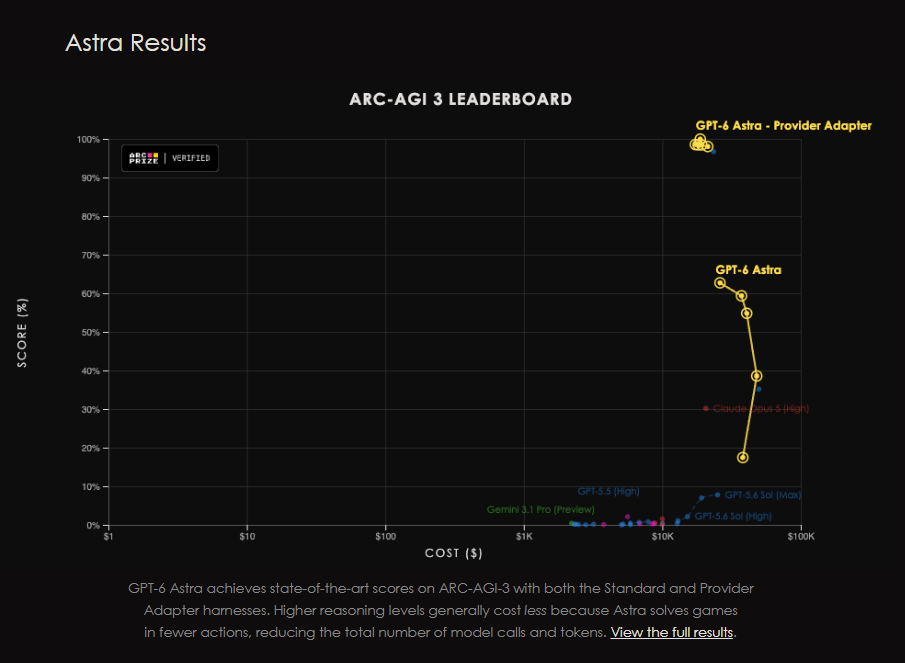
source: https://arcprize.org/results/openai-gpt-6-astra

## 📖 The handbook

The handbook follows one level, the first level of the game sk48, as it is played by the open Milestone-2 harness and by Fable 5, the strongest public agent (it runs in the PRO-LONG system from Duke). It then opens the harness itself: what the model reads, how it sees the board, what it remembers, how 110 games share one GPU, and which guards stop useless actions. It closes with the first tests of changes to the harness.

Its value is in the detail. Statements are marked by reliability (seen in the records, estimate, not checked), and the figures are built from the data of real runs. That makes it possible to reason about what a harness does instead of guessing from leaderboard scores. The harness layer described further down comes straight from it: the habits of Fable that the layer copies (notes with expected outcomes, small probes, the budget written down early) are read off the logs in chapter 2.

<div style="border:1px solid rgba(128,128,128,.35);border-radius:16px;padding:24px 28px;margin:14px 0;">
<div style="font-size:12px;letter-spacing:1.6px;text-transform:uppercase;opacity:.65;">Handbook &middot; 3 parts &middot; 12 chapters &middot; 90 pages &middot; English</div>
<div style="font-size:23px;font-weight:800;margin:8px 0 10px 0;line-height:1.25;">How an open agent plays ARC-AGI-3, and how its harness works</div>
<div style="opacity:.88;line-height:1.6;">One level through two systems&rsquo; eyes, where time and tokens go, the harness from the inside, and the first test of an idea.</div>
<div style="margin-top:16px;line-height:2;">
📦&nbsp; Dataset (PDF of the handbook and the submission notebook): <a href="https://www.kaggle.com/datasets/leoprovorov/arc-agi-3-fable-harness-analytical-handbook">kaggle.com/datasets/leoprovorov/arc-agi-3-fable-harness-analytical-handbook</a><br>
👍&nbsp; If the handbook is useful, an upvote on the dataset helps other people find it.
</div>
</div>

👇 **Read it here.** Scroll inside the frame. The menu on the left jumps between chapters, **A&minus; / A+** change the text size, **◐** switches light, dark and sepia themes, and a click on a figure enlarges it.

In [ ]:
# The handbook reader is the file handbook_reader.html of the attached dataset.
import glob
import html
import os
from IPython.display import HTML, display

candidates = [os.environ.get("HANDBOOK_READER", "")] + sorted(glob.glob("/kaggle/input/**/handbook_reader.html", recursive=True))
path = next((p for p in candidates if p and os.path.exists(p)), None)
if path:
    reader = open(path, encoding="utf-8").read()
    display(HTML(
        '<iframe srcdoc="' + html.escape(reader, quote=True) + '" width="100%" height="820" '
        'style="border:1px solid rgba(128,128,128,.35);border-radius:12px;background:#fff"></iframe>'))
else:
    display(HTML("<p>The reader is part of the handbook dataset. Attach it with <b>Add Input</b>, then run this cell again.</p>"))

### Contents of the handbook

**Introduction** (page 3). The competition, the scoring rule, the runs discussed and the vocabulary.

**Part I &middot; One level, two systems, and what affects the result**

| Chapter | What it covers | Page |
|---|---|---|
| 1. One level through the baseline system's eyes | A move-by-move account of one first level (sk48) as the open harness plays it: what the model receives, what it does, where its reasoning bends. | 8 |
| 2. The same level through Fable's eyes | How the strongest public agent works and how it plays the same level; the point where its reasoning separates from the baseline system's. | 18 |
| 3. What can be learned from strong systems | Ways of learning from strong agents' traces, which of them are practical, and how to test an idea on a single task. | 25 |
| 4. Where the time goes and what matters | Server time and game time, the cost of waiting, and what moves the score. | 32 |

**Part II &middot; The harness from the inside**

| Chapter | What it covers | Page |
|---|---|---|
| 5. What the harness consists of and how one game runs | A map of the harness and the life of one game. | 42 |
| 6. What the model reads and what it can do | The anatomy of one request, the single Python tool, the limits. | 48 |
| 7. How the model sees the game | Letters, regions, pictures, frame differences and animation. | 53 |
| 8. What the model remembers and forgets | The context window, the trimming rule, what survives. | 58 |
| 9. The queue for a slot and the priorities | How games share one server, the priority formula, what it did to a stuck game. | 62 |
| 10. Guards against empty actions, and plumbing | No-op guards, action names, the server protocol, where state is stored. | 66 |

**Part III &middot; The changes and the first test**

| Chapter | What it covers | Page |
|---|---|---|
| 11. The changes to the harness: what goes where | The first two changes and where each hooks into a turn. | 70 |
| 12. First test: a journal that replaced the history | A 15-game run of the first change: where it fell behind, what is established and what is not. | 78 |

**Glossary** (page 87). Every term used in the handbook.

## 🧮 Two pieces of math behind everything else

### 1 &middot; How a game is scored

A game has $n$ levels. For level $i$ the organisers measured how many actions people need, $h_i$ (a typical value, the *human baseline*). If an agent clears it in $a_i$ actions:

$$ s_i=\min\!\Big(1.15,\ \big(h_i/a_i\big)^{2}\Big)\ \text{ if level } i \text{ is cleared},\qquad s_i=0\ \text{ otherwise.} $$

The game score weights each level by its index and is capped by the share of weight that was actually cleared:

$$ S \;=\; 100\cdot\min\!\left(\frac{\sum_i i\,s_i}{W},\ \frac{\sum_{i\ \text{cleared}} i}{W}\right),\qquad W=\frac{n(n+1)}{2}. $$

The total is the mean of $S$ over the games. Three things follow:

* The penalty is **quadratic**: twice the human's actions earns 25% of a level, not 50%.
* A level can earn at most 115%, and the cap means that efficiency on early levels never buys back a level that was not cleared. Each new level matters more than saving actions on old ones.
* Every action counts, **UNDO included**. UNDO does not refill the step budget, but it is a scored action.

To check that the rule is right, the next cell reproduces three real results from a ten-copy run of sk48 (8 levels, so $W=36$).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

NAVY, TEAL, AMBER, CORAL, GREY, SAND = "#0b2545", "#1f7a8c", "#e9a23b", "#d1495b", "#8d99ae", "#f6f3ec"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 130, "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#6b7a8d", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#26323f", "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "legend.frameon": False,
})

def level_score(h, a):
    return min(1.15, (h / a) ** 2)

def game_score(norms, actions):
    # actions[i] = actions used on level i+1, or None if that level was not cleared
    n = len(norms); W = n * (n + 1) / 2
    raw = sum((i + 1) * level_score(norms[i], a) for i, a in enumerate(actions) if a)
    cap = sum((i + 1) for i, a in enumerate(actions) if a)
    return 100 * min(raw, cap) / W, 100 * raw / W, 100 * cap / W

SK48 = [61, 177, 101, 103, 230, 181, 125, 92]           # human baselines (actions) of the 8 levels of sk48
RUNS = {"copy 4": ([21, 165], 8.33), "copy 3": ([114, 97], 7.18), "copy 7": ([96, 45, 48], 16.67)}

print(f"{'run':8s} {'levels cleared':>14s} {'raw %':>7s} {'cap %':>7s} {'score':>7s}   recorded")
rows = {}
for name, (acts, recorded) in RUNS.items():
    final, raw, cap = game_score(SK48, acts)
    rows[name] = (raw, cap, final)
    assert abs(final - recorded) < 0.01, (name, final, recorded)
    print(f"{name:8s} {len(acts):14d} {raw:7.2f} {cap:7.2f} {final:7.2f}   {recorded}")
print("all three match the recorded scores")

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.1), gridspec_kw={"width_ratios": [1.35, 1]})
a = np.arange(8, 300)
ax[0].plot(a, [level_score(61, x) for x in a], color=NAVY, lw=2.4)
ax[0].axhline(1.15, color=GREY, lw=1, ls=":")
ax[0].text(300, 1.17, "cap 1.15", ha="right", color="#59667a", fontsize=9)
for x, lab, dx, dy in ((61, "human: 61 actions\n= 100%", 14, -0.04), (122, "2x human = 25%", 14, 0.05)):
    ax[0].plot([x], [level_score(61, x)], "o", color=CORAL, ms=7)
    ax[0].annotate(lab, (x, level_score(61, x)), xytext=(x + dx, level_score(61, x) + dy), fontsize=9, color=CORAL)
solved = [24, 19, 78, 114, 21, 38, 140, 96, 77]          # actions on level 1 of the nine copies that cleared it
ax[0].plot(solved, [level_score(61, x) for x in solved], "|", color=TEAL, ms=16, mew=2.4)
ax[0].text(300, 0.62, "teal ticks: the nine copies\nthat cleared level 1", ha="right", color=TEAL, fontsize=9.5)
ax[0].set_xlabel("actions used on the level"); ax[0].set_ylabel("level score $s_i$")
ax[0].set_title("A level pays quadratically in actions (sk48, level 1)", loc="left")
ax[0].set_ylim(0, 1.45); ax[0].set_xlim(0, 300)

x = np.arange(len(rows)); w = 0.26
raws = [rows[k][0] for k in rows]; caps = [rows[k][1] for k in rows]; fins = [rows[k][2] for k in rows]
ax[1].bar(x - w, raws, w, color=AMBER, label="raw (weighted sum)")
ax[1].bar(x, caps, w, color=GREY, label="cap (share of levels cleared)")
ax[1].bar(x + w, fins, w, color=NAVY, label="score = min(raw, cap)")
for xi, v in zip(x + w, fins):
    ax[1].text(xi, v + 0.3, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold", color=NAVY)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{k}\n({len(RUNS[k][0])} levels)" for k in rows])
ax[1].set_ylabel("game score, %"); ax[1].set_title("The cap decides when the raw sum is high", loc="left")
ax[1].legend(fontsize=8.5, loc="upper left"); ax[1].set_ylim(0, 21)
plt.tight_layout(); plt.show()

**How to read the figure.** *Left:* the horizontal axis is the number of actions a copy spent on level 1 of sk48, the vertical axis is the level score $s_1$. The curve is $\min(1.15,(61/a)^2)$ with the human baseline of 61 actions. The two red dots mark reference points: 61 actions score 1.0 (100%), 122 actions score 0.25. The teal ticks sit on the curve at the actions spent by the nine copies that cleared the level. *Right:* for three real results (copies 4, 3 and 7) there are three bars each. Orange is the raw weighted sum, grey is the cap (the share of level weights that was cleared) and navy is the final score, the lower of the two.

**What it shows.** Fast copies sit on the flat top of the curve (1.15 is the maximum), while a copy that needs 114 actions already falls to 0.29. Copy 4 cleared two levels quickly and its raw sum (9.58) exceeds the cap, so it scores the cap, 8.33. Copy 3 was slow on level 1, so its raw sum (7.18) stays under the cap and is its score.

### 2 &middot; Why tokens are the real currency

The real run gives every game a fixed slice of one GPU. My estimate is $626\ \text{tokens/s} \times 31{,}800\ \text{s} \div 110\ \text{games} \approx 181{,}000$ generated tokens per game. Score grows with tokens and then flattens. With $t$ the tokens per game and $S(t)$ the mean score, the *local elasticity*

$$ \varepsilon(t)=\frac{d\ln S}{d\ln t} $$

says that 10% more tokens buy about $10\,\varepsilon\,\%$ more score. The curve below has 13 points printed by a public Kaggle notebook (the "sovereign agent" notebook) over the 25 public games; the elasticity is computed between neighbouring points.

In [ ]:
# 13 points: tokens per game (thousands) -> mean score over the 25 public games (public notebook "sovereign agent")
CURVE = [(14.8, 1.55), (30.2, 5.21), (45.8, 9.82), (60.7, 15.86), (74.8, 25.87), (90.6, 29.99), (105.1, 32.31),
         (117.5, 36.51), (132.7, 39.07), (145.3, 43.93), (162.8, 47.24), (173.4, 48.05), (192.5, 49.25)]
t = np.array([c[0] for c in CURVE]); s = np.array([c[1] for c in CURVE])
eps = np.diff(np.log(s)) / np.diff(np.log(t))            # elasticity between neighbouring points
mid = np.sqrt(t[:-1] * t[1:])
print("elasticity below 60k tokens :", np.round(eps[mid < 60], 2))
print("elasticity above 160k tokens:", np.round(eps[mid > 160], 2))

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.1), gridspec_kw={"width_ratios": [1.25, 1]})
ax[0].plot(t, s, "-o", color=NAVY, lw=2.2, ms=5)
ax[0].axvline(181, color=CORAL, ls="--", lw=1.4)
ax[0].text(178, 4, "real run\n~181k tokens per game\n(my estimate)", color=CORAL, ha="right", fontsize=9)
ax[0].set_xlabel("generated tokens per game, thousands"); ax[0].set_ylabel("mean score, 25 public games")
ax[0].set_title("More tokens help, with diminishing returns", loc="left"); ax[0].set_ylim(0, 56)
ax[1].bar(range(len(eps)), eps, color=[TEAL if m < 160 else CORAL for m in mid])
ax[1].axhline(1, color=GREY, lw=1, ls=":")
ax[1].set_xticks(range(len(eps))); ax[1].set_xticklabels([f"{m:.0f}" for m in mid], fontsize=8, rotation=45)
ax[1].set_xlabel("tokens per game, thousands (middle of each segment)"); ax[1].set_ylabel(r"elasticity $\varepsilon$")
ax[1].set_title("Every token is worth far less near the real budget", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**How to read the figure.** *Left:* the horizontal axis is the generated tokens per game (thousands), the vertical axis is the mean score over the 25 public games; each dot is one measurement and the red dashed line marks the estimated budget of the real run. *Right:* each bar is the elasticity between two neighbouring dots on the left, labelled with the middle of that segment in thousands of tokens. The dotted line at 1 means "the score grows exactly as fast as the tokens"; teal bars lie below 160k tokens, red bars above.

**What it shows.** Below about 70k tokens every segment is above 1.5, so extra tokens are repaid more than proportionally. Above that the elasticity is noisy, mostly between 0.5 and 1.3, and the two red bars nearest the real budget are 0.27 and 0.24.

Below about 60k tokens one more percent of tokens buys 1.5 to 1.7 percent more score; in the last segments, near the real budget, it buys about a quarter of a percent. Two consequences shape the rest of the notebook:

1. A harness change that adds text to every request pays for itself only if it beats the flat part of this curve. Changes should therefore add little text, and add it only where a game is stuck.
2. Methods should be compared at the **same number of generated tokens per game**, not the same wall-clock time. I borrowed this from the write-up of a third-place Milestone-2 entry (rellik13), who also found that one run says little: the same notebook submitted three times scored 5.02, 5.50 and 6.42.

## 🔧 The solution &mdash; what it is and how it differs from the original

<div style="border-left:5px solid #d1495b;background:rgba(209,73,91,0.09);border-radius:10px;padding:4px 22px;margin:16px 0;">

**A heads-up for newcomers.** From here the notebook goes straight into the harness, which can be a lot if ARC-AGI-3 is new to you. I have study material that explains the game and each part of the harness step by step (chapters 5 to 10 of the handbook are exactly that). If something is unclear, **ask in the comments**. I will point you to the right part and share the other pieces that explain the architecture as a whole. They help with learning, and they help when you want to explore a new hypothesis of your own.

</div>

### The lineage

The solution is a small, switchable patch on top of the open Milestone-2 winner:

**Tufa Labs&rsquo; Duck harness** (Jeroen Cottaar) &rarr; **Franzen&rsquo;s Milestone-2 notebook** (Qwen3.8-Flash-Next served with SGLang on one RTX PRO 6000, Intel AutoRound 4-bit weights, an MTP draft model for speculative decoding) &rarr; **this solution**.

| | Original (Milestone-2 winner) | This solution |
|---|---|---|
| Model and server | Qwen3.8-Flash-Next, 4-bit, MTP draft model, SGLang | identical |
| Harness | Duck harness with Franzen's patch | identical, plus one patch |
| Schedule | 110 games, one server, queue and priorities | identical |
| Prompts | system prompt and openers as shipped | system prompt untouched |
| **New** | | **the Fable layer:** indicator notes, a pinned level log, a low-budget alert |

The patch adds about 200 lines to the harness file and one self-contained module of about 540 lines. Every hook sits behind an environment flag and is wrapped so that an error means &ldquo;do nothing&rdquo;. With the flag off, a local check on the real harness gave identical openers and identical request sizes. The changes are small and can be tested one by one.

### Where the ideas come from

Chapter 2 of the handbook follows Fable on sk48 level 1: ten rounds, 32 actions (the human baseline is 61). Five habits stand out. For each I asked: *can the harness do this for the model without asking the model for anything?*

| What Fable does (traces, chapter 2) | Mechanism in this solution | When it acts |
|---|---|---|
| Reads the legend every round (&ldquo;legend red icon centre turns white = hit registered&rdquo;, rounds 4, 7, 9) | **Indicator notes:** the harness reports a changed legend or tray patch and which action changed it | after 15k tokens on a level |
| Writes the *outcome* of every probe into its notes and corrects wrong rules in place (&ldquo;FAILED blue link&hellip;&rdquo;) | **Pinned level log:** what each key did, in which board state; indicator history; UNDO count | after 30k tokens on a level, refreshed every 40k |
| Writes the step budget down in round 3 (&ldquo;64 px &asymp; 192 actions, plenty&rdquo;) | **Budget estimate** with an alert when little is left | only at &le;25% left or &le;12 actions |
| Sends 1&ndash;3 actions while a rule is unconfirmed, up to 20 for verified ones | **Five protocol lines** inside the level log (the system prompt stays untouched) | with the log |
| Keeps the whole log outside the conversation and searches it | not copied; the harness keeps the full history and adds a compact digest of the cleared levels | with the log |

<div style="border-left:5px solid #0b2545;background:rgba(11,37,69,0.08);border-radius:10px;padding:4px 22px;margin:16px 0;">

**Three rules taken from other people's measurements and from an earlier test.**

* *Add facts, not advice.* In the third-place write-up, blocks of advice cut the public score from 6.42 to 4.16 and from 13.40 to 9.98; the biggest gain (+8.0) came from keeping more of the agent's own recent history, and a rule pinned from the previous level gave +2.8 (their numbers).
* *Never remove history.* The first idea, a journal that **replaced** the history, finished with 23 cleared levels against 46 for the unchanged harness on the same 15 hard games (chapter 12).
* *Touch only levels that drag on.* A level solved quickly gets nothing.

</div>

### Mechanism 1 &middot; Indicator notes

**What gets missed.** On sk48 the bottom panel shows the three blocks as icons. When the beam threads a block, the centre of its icon turns white: the game's only direct signal that something went right. Fable reads it in rounds 4, 7 and 9. The open harness shows the model every frame, but the mark is a 2&times;2 patch among 4096 cells.

In [ ]:
# Real frames of copy 4 of my ten-copy run: the bottom panel (rows 54-63, columns 14-49) at five moments of level 1.
LETTERS = "WwgGcBMPRbSYOrNp"                      # letter = colour id, the legend printed in the model's instruction
PAL = {0: (255, 255, 255), 1: (204, 204, 204), 2: (153, 153, 153), 3: (102, 102, 102), 4: (51, 51, 51), 5: (0, 0, 0),
       6: (229, 58, 163), 7: (255, 123, 204), 8: (249, 60, 49), 9: (30, 147, 255), 10: (136, 216, 241), 11: (255, 220, 0),
       12: (255, 133, 27), 13: (146, 18, 49), 14: (79, 204, 48), 15: (163, 86, 214)}

def grid(text):
    return [[LETTERS.index(ch) for ch in row] for row in text.strip().split("\n")]

def rgb(g):
    return np.array([[PAL[v] for v in row] for row in g], dtype=np.uint8)

TRAY = {
    0: """
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
ccccccMMMMMMcccccccccccccccccccccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMWMMWwgRRRRwgNNNNwgbbbbwcccccc
ccccccMWMMWgwRRRRgwNNNNgwbbbbgcccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMMMMMMcccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
""",
    10: """
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
ccccccMMMMMMcccccccccccccccccccccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMWMMWwgRWWRwgNNNNwgbbbbwcccccc
ccccccMWMMWgwRWWRgwNNNNgwbbbbgcccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMMMMMMcccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
""",
    14: """
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
ccccccMMMMMMcccccccccccccccccccccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMWMMWwgRWWRwgNNNNwgbbbbwcccccc
ccccccMWMMWgwRWWRgwNNNNgwbbbbgcccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMMMMMMcccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
""",
    18: """
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
ccccccMMMMMMcccccccccccccccccccccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMWMMWwgRWWRwgNWWNwgbbbbwcccccc
ccccccMWMMWgwRWWRgwNWWNgwbbbbgcccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMMMMMMcccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
""",
    20: """
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
ccccccMMMMMMcccccccccccccccccccccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMWMMWwgRWWRwgNWWNwgbbbbwcccccc
ccccccMWMMWgwRWWRgwNWWNgwbbbbgcccccc
ccccccMWWWWMcRRRRccNNNNccbbbbccccccc
ccccccMMMMMMcccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccc
""",
}
LABEL = {0: "action 0: start, no marks",
         10: "action 10: the beam reached the red block;\nthe centre of its icon turns white",
         14: "action 14: 'left' pulled the beam in, the red\nblock follows, the mark stays",
         18: "action 18: the beam reached the green block;\nred and green both marked",
         20: "action 20: chain lifted 'up';\nblue has no mark yet"}

fig, axes = plt.subplots(5, 1, figsize=(8.6, 6.4))
for a, k in zip(axes, TRAY):
    a.imshow(rgb(grid(TRAY[k])), interpolation="nearest"); a.axis("off")
    a.text(1.03, 0.5, LABEL[k], transform=a.transAxes, va="center", fontsize=9.5, color="#26323f")
fig.suptitle("The only direct progress signal of sk48 level 1: marks in the bottom panel", x=0.02, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

**How to read the figure.** Five snapshots of the bottom panel of copy 4 on level 1 (rows 54 to 63, columns 14 to 49 of the frame), from top to bottom in time; the text on the right says which action each snapshot follows. In every snapshot the pink square on the left is the shooter, the red, green and blue squares are the three blocks, and the dashed grey segments between them are the links of the chain. A white square in the centre of a block icon is a mark.

**What it shows.** The marks are the only direct feedback the game gives on this level. A mark appears when the beam reaches the block (rows 2 and 4), stays while the block is held (row 3), and the blue block still has none when the chain is lifted (row 5).

**What the harness can do.** Compare two consecutive frames and report small patches that changed *far* from where things moved. Let $D$ be the set of cells that differ between the two frames.

1. Split $D$ into 8-connected components.
2. Drop components that look like a timer bar: within 6 cells of the frame edge and part of a straight run of one colour at least 12 cells long.
3. Merge components whose bounding boxes are at most 8 cells apart into *clusters*; the biggest cluster is the main activity $M$ (the thing that moved).
4. Report a cluster $C\neq M$ when $2\le |C|\le 16$, its box is at most $6\times 6$, the gap to $M$ is at least 8 cells, and it is not a vacated/occupied pair of equal size (that would be a small object that moved).
5. Remember the first colour of each reported box. A later change back to it is reported as **lost** (a mark that was earned may be gone); a repeat of an earlier change is reported as **again**.

The cell below runs exactly these five steps on the real frames before and after action 10 of copy 4 (the beam reaches the red block).

In [ ]:
BEFORE = '''
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMMMMMMccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWWWWMcccccccccccccccccccccccccRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWMMWwgwwgwwgwwgwwgwwgwwgwwgwwcRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWMMWgwwgwwgwwgwwgwwgwwgwwgwwgcRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWWWWMcccccccccccccccccccccccccRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMMMMMMccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
ggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggGG
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
ccccccccccccccccccccMMMMMMcccccccccccccccccccccccccccccccccccccc
ccccccccccccccccccccMWWWWMcRRRRccNNNNccbbbbccccccccccccccccccccc
ccccccccccccccccccccMWMMWwgRRRRwgNNNNwgbbbbwcccccccccccccccccccc
ccccccccccccccccccccMWMMWgwRRRRgwNNNNgwbbbbgcccccccccccccccccccc
ccccccccccccccccccccMWWWWMcRRRRccNNNNccbbbbccccccccccccccccccccc
ccccccccccccccccccccMMMMMMcccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
'''
AFTER = '''
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMMMMMMccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWWWWMcccccccccccccccccccccccccRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWMMWwgwwgwwgwwgwwgwwgwwgwwgwwgRRRRwBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWMMWgwwgwwgwwgwwgwwgwwgwwgwwgwRRRRgBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMWWWWMcccccccccccccccccccccccccRRRRcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBMMMMMMccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccbbbbcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBcccccccccccccccccccccccccNNNNcBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBGGBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBggBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBccccccccccccccccccccccccccccccBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
BBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBBB
gggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggGGG
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
ccccccccccccccccccccMMMMMMcccccccccccccccccccccccccccccccccccccc
ccccccccccccccccccccMWWWWMcRRRRccNNNNccbbbbccccccccccccccccccccc
ccccccccccccccccccccMWMMWwgRWWRwgNNNNwgbbbbwcccccccccccccccccccc
ccccccccccccccccccccMWMMWgwRWWRgwNNNNgwbbbbgcccccccccccccccccccc
ccccccccccccccccccccMWWWWMcRRRRccNNNNccbbbbccccccccccccccccccccc
ccccccccccccccccccccMMMMMMcccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
cccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc
'''
B, A = grid(BEFORE), grid(AFTER)

def diff_cells(x, y):
    return [(r, c) for r in range(64) for c in range(64) if x[r][c] != y[r][c]]

def components8(cells):
    left, comps = set(cells), []
    while left:
        stack = [left.pop()]; comp = list(stack)
        while stack:
            r, c = stack.pop()
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):
                    n = (r + dr, c + dc)
                    if n in left:
                        left.remove(n); stack.append(n); comp.append(n)
        comps.append(sorted(comp))
    return comps

def box_of(cells):
    rs, cs = [p[0] for p in cells], [p[1] for p in cells]
    return (min(rs), min(cs), max(rs), max(cs))

def gap(b1, b2):
    return max(b2[0] - b1[2], b1[0] - b2[2], 0, b2[1] - b1[3], b1[1] - b2[3])

def run_len(g, r, c, dr, dc, v):
    n = 0; r += dr; c += dc
    while 0 <= r < 64 and 0 <= c < 64 and g[r][c] == v:
        n += 1; r += dr; c += dc
    return n

def bar_like(x, y, comp):
    r0, c0, r1, c1 = box_of(comp)
    if min(r0, c0, 63 - r1, 63 - c1) > 6:
        return False                                   # a bar sits at the edge of the frame
    for g in (x, y):
        v = g[comp[0][0]][comp[0][1]]
        if any(g[r][c] != v for r, c in comp):
            continue
        horiz = run_len(g, r0, c0, 0, -1, v) + run_len(g, r0, c1, 0, 1, v) + (c1 - c0 + 1)
        vert = run_len(g, r0, c0, -1, 0, v) + run_len(g, r1, c0, 1, 0, v) + (r1 - r0 + 1)
        if horiz >= 12 or vert >= 12:
            return True
    return False

def explain(x, y):
    comps = components8(diff_cells(x, y))
    bars = [c for c in comps if bar_like(x, y, c)]
    kept = [c for c in comps if c not in bars]
    boxes = [box_of(c) for c in kept]
    parent = list(range(len(kept)))                    # merge boxes at most 8 cells apart
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    for i in range(len(kept)):
        for j in range(i + 1, len(kept)):
            if gap(boxes[i], boxes[j]) <= 8:
                parent[find(i)] = find(j)
    groups = {}
    for i in range(len(kept)):
        groups.setdefault(find(i), []).append(kept[i])
    clusters = sorted(groups.values(), key=lambda g: (sum(map(len, g)), len(g)), reverse=True)
    main = clusters[0]; mbox = box_of([p for c in main for p in c])
    report = []
    for g in clusters[1:]:
        pts = [p for c in g for p in c]; b = box_of(pts)
        size_ok = 2 <= len(pts) <= 16 and b[2] - b[0] < 6 and b[3] - b[1] < 6
        sizes = sorted(len(c) for c in g)
        moved_pair = len(g) >= 2 and abs(sizes[0] - sizes[-1]) <= 1
        report.append((pts, b, size_ok and gap(mbox, b) >= 8 and not moved_pair))
    return bars, main, report

bars, main, report = explain(B, A)
print("changed cells:", len(diff_cells(B, A)), "| timer-like pieces dropped:", len(bars), "| main activity:", sum(map(len, main)), "cells")
for pts, b, ok in report:
    old, new = LETTERS[B[pts[0][0]][pts[0][1]]], LETTERS[A[pts[0][0]][pts[0][1]]]
    print(f"cluster of {len(pts)} cells at rows {b[0]}-{b[2]}, cols {b[1]}-{b[3]}: {old} -> {new}  ->  {'INDICATOR NOTE' if ok else 'ignored'}")

img = rgb(A).copy()
fig, ax = plt.subplots(1, 3, figsize=(12.6, 4.5))
ax[0].imshow(rgb(B), interpolation="nearest"); ax[0].set_title("before action 10", loc="left")
ax[1].imshow(rgb(A), interpolation="nearest"); ax[1].set_title("after action 10 (RIGHT)", loc="left")
dim = (rgb(A) * 0.25 + 190).astype(np.uint8)
ax[2].imshow(dim, interpolation="nearest"); ax[2].set_title("what the detector sees", loc="left")
def paint(cells, color):
    for r, c in cells:
        ax[2].add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=color, lw=0))
for c in bars: paint(c, GREY)
for c in main: paint(c, NAVY)
for pts, b, ok in report:
    paint(pts, TEAL if ok else AMBER)
    if ok:
        ax[2].add_patch(plt.Rectangle((b[1] - 2.5, b[0] - 2.5), b[3] - b[1] + 6, b[2] - b[0] + 6, fill=False, ec=TEAL, lw=2))
        ax[2].annotate("indicator note", (b[3] + 3.5, b[0]), xytext=(34, 47), color=TEAL, fontweight="bold", fontsize=10,
                       arrowprops=dict(arrowstyle="->", color=TEAL))
for a in ax: a.axis("off")
ax[2].text(0.0, -0.06, "navy: main activity (beam)   teal: indicator   grey: timer-like", transform=ax[2].transAxes, fontsize=9, color="#26323f")
plt.tight_layout(); plt.show()

**How to read the figure.** *Left and middle:* the full 64×64 board before and after one action (RIGHT, action 10 of copy 4), in the colours of the game. *Right:* the same board faded, with the cells that changed painted by the role the rules give them. Navy is the main activity (the tip of the beam, 4 cells in two pieces), grey is a timer-like piece (one cell of the step bar), teal is the indicator candidate (the 2×2 patch in the bottom panel, boxed and labelled). The lines printed above the figure give the same decision as text.

**What it shows.** One action changed 9 cells in four places. The rules keep a single patch: the one in the bottom panel, which is compact and far from the beam. The harness turns it into a note like the one quoted below.

The beam tip (navy) is the main activity; the one-cell tick of the step bar is recognised as timer-like and dropped; the 2&times;2 tray patch is far from the main activity and compact, so it becomes a note such as *&ldquo;after action 10 (RIGHT) a small patch away from the moved objects changed: rows 58-59, cols 28-29, red to white&rdquo;*.

**Is it worth a line in the prompt?** In my ten-copy run, the number of times a threaded block left the beam (a mark in the panel went out) goes together with the tokens spent on level 1:

In [ ]:
# Ten independent copies of sk48 level 1 (48 minutes each, no queue). tokens = generated tokens spent on level 1.
COPIES = [  # (copy, times a mark went out, tokens on level 1, cleared it?)
    (0, 0, 21386, True), (1, 0, 28512, True), (2, 2, 135899, True), (3, 2, 122330, True), (4, 0, 21176, True),
    (5, 1, 44017, True), (6, 1, 84579, True), (7, 2, 92941, True), (8, 1, 103342, True), (9, 4, 169819, False)]
lost = np.array([c[1] for c in COPIES]); tok = np.array([c[2] for c in COPIES], float)

def ranks(v):
    order = np.argsort(v, kind="stable"); r = np.empty(len(v)); i = 0; vs = np.asarray(v)[order]
    while i < len(v):
        j = i
        while j + 1 < len(v) and vs[j + 1] == vs[i]:
            j += 1
        r[order[i:j + 1]] = (i + j) / 2 + 1; i = j + 1
    return r

rl, rt = ranks(lost), ranks(tok)
rho = np.corrcoef(rl, rt)[0, 1]
rng = np.random.default_rng(0)
perm = np.array([abs(np.corrcoef(rl, rt[rng.permutation(10)])[0, 1]) for _ in range(100000)])
p_val = float((perm >= abs(rho)).mean())
print(f"Spearman rho = {rho:.2f}  (permutation p = {p_val:.4f}, n = 10 copies of one game)")

fig, ax = plt.subplots(figsize=(7.6, 4.8))
LABEL_AT = {0: (-42, -12), 1: (7, 6), 4: (9, -13)}                                                    # label offsets in points
NUDGE = {0: -0.13, 4: 0.13, 2: -0.1, 3: 0.1, 5: 0.0, 6: -0.1, 8: 0.1, 7: 0.0, 1: 0.0, 9: 0.0}   # horizontal offsets so labels stay readable
for (cp, k, tk, ok) in COPIES:
    jx = k + NUDGE[cp]
    ax.plot(jx, tk / 1000, "o" if ok else "X", color=TEAL if ok else CORAL, ms=11 if ok else 13, alpha=.9)
    dx, dy = LABEL_AT.get(cp, (7, 5))
    ax.annotate(f"copy {cp}", (jx, tk / 1000), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color="#46546a")
ax.set_xlabel("times a mark in the bottom panel went out on level 1"); ax.set_ylabel("generated tokens on level 1, thousands")
ax.set_xticks(range(5)); ax.set_xlim(-0.5, 4.6); ax.set_ylim(0, 190)
ax.set_title(f"The more often a mark went out, the more the level cost (rho = {rho:.2f})", loc="left")
ax.plot([], [], "o", color=TEAL, label="cleared"); ax.plot([], [], "X", color=CORAL, label="not cleared in 48 min"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**How to read the figure.** Each dot is one of the ten copies (the label is the copy number). The horizontal axis is how many times a mark in the bottom panel went out on level 1, that is how many times a threaded block left the beam. The vertical axis is the generated tokens spent on level 1, in thousands. A teal circle is a copy that cleared the level, the red cross is the copy that did not clear it in 48 minutes. Dots with equal values are nudged sideways so that the labels stay readable.

**What it shows.** The copies that never lost a mark finished in 21 to 29 thousand tokens, those that lost one or two marks needed 44 to 136 thousand, and the copy that lost four marks spent 170 thousand and did not finish. The rank correlation is $\rho=0.93$ (permutation test $p=0.0004$).

<div style="border-left:5px solid #e9a23b;background:rgba(233,162,59,0.15);border-radius:10px;padding:4px 22px;margin:16px 0;">

**Read this with care.** $n=10$ copies of one game, an observation and not an experiment. Longer play also means more chances to lose a mark, so the arrow of causation can run either way. What the figure supports is a hypothesis: *if the harness tells the model the moment a mark goes out, does the level cost fewer tokens?*

</div>

### Mechanism 2 &middot; A pinned level log when a level drags on

**Trigger.** Let $T_\ell$ be the generated tokens spent on the current level. The notes start at $T_\ell\ge 15{,}000$. The log is written once at $T_\ell \ge 30{,}000$ and rewritten every further $\Delta = 40{,}000$ tokens while the level stays open; a new level starts clean. The share of games still on a level after $t$ tokens, $U(t)=\frac1N\#\{j: T_j>t\}$, shows what that gate touches:

In [ ]:
solved_tokens = np.array([c[2] for c in COPIES])                    # copy 9 never cleared it (censored at 170k)
grid_t = np.linspace(0, 180000, 721)
U = np.array([(solved_tokens > x).mean() for x in grid_t])
fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.step(grid_t / 1000, U * 100, where="post", color=NAVY, lw=2.4)
for x, lab, col, ty in ((15, "notes\n15k", AMBER, 22), (30, "log pinned\n30k", CORAL, 6), (70, "refresh\n70k", CORAL, 6), (110, "refresh\n110k", CORAL, 6)):
    ax.axvline(x, color=col, ls="--", lw=1.3); ax.text(x + 1.5, ty, lab, color=col, fontsize=9)
for x in (15, 30, 60, 100):
    u = (solved_tokens > x * 1000).mean() * 100
    ax.plot([x], [u], "o", color=NAVY, ms=6); ax.annotate(f"{u:.0f}%", (x, u), xytext=(5, 6), textcoords="offset points", fontsize=9, color=NAVY)
ax.set_xlabel("generated tokens spent on level 1, thousands"); ax.set_ylabel("copies still on level 1, %")
ax.set_title("The gate leaves quick solves alone: 3 of 10 copies never see the log", loc="left"); ax.set_ylim(0, 108); ax.set_xlim(0, 180)
plt.tight_layout(); plt.show()
print("copies still on level 1 after 15k / 30k / 60k / 100k tokens:", [int((solved_tokens > x * 1000).sum()) for x in (15, 30, 60, 100)], "of 10")

**How to read the figure.** The step curve is the share of copies that are still working on level 1 after a given number of tokens (vertical axis, per cent); it drops each time a copy clears the level. The dashed vertical lines show when the layer acts: amber at 15k tokens (notes start), red at 30k (the log is pinned) and at 70k and 110k (it is refreshed). The dots mark the share at 15k, 30k, 60k and 100k tokens.

**What it shows.** At 30k tokens 7 of the 10 copies are still on level 1 and would get a log. The three copies that finished at 21k, 21k and 29k tokens never see it.

**Contents.** The harness writes the log from the recorded frames, so nothing in it is the model's own claim: per key how often it was pressed, how often it changed the board, how often it did nothing, and the typical shift; the indicator history; the UNDO count; the step budget; a digest of what the cleared levels taught; five lines of working protocol (two or three readings of the goal at once, the cheapest probe for each, check moved objects / marks / step bar after every probe, short batches while a rule is unconfirmed, restore a lost mark before building further).

**Placement.** The log is appended to the history as a user/assistant pair. Trimming removes the history from the front, so the pair survives until it has become the oldest block; if a trim then drops it, the harness puts it back at the head (right after the system prompt). This repeats until the level changes. No model call is made for it and the server seat is not released.

**Three lessons from the first attempt, built in.**

1. *Computed, not written by the model.* The journal of the first attempt was written by the model and recorded conditional results as refuted.
2. *Pinned, not substituted.* The unchanged history stays.
3. *Restored after the eviction check.* Replacing history counted as an eviction, which hands the server seat to another game: 27 pauses longer than 4 minutes, 30% of all game minutes, right after the journals. The layer puts its pair back only after that check, so restoring it can never count as an eviction.

**Cost.** About 0.6 to 1k tokens, under 1% of the 118,272-token request budget (131,072 window minus 12,288 for the answer minus 512 reserve). A refresh rebuilds the cached prefix once per 40k tokens.

Where the layer sits in the context of one request (schematic):

In [ ]:
from matplotlib.patches import FancyBboxPatch

def bar(ax, y, parts, title):
    x = 0.0
    ax.text(0, y + 0.62, title, fontsize=10.5, fontweight="bold", color="#26323f")
    for label, w, col, tc, dashed in parts:
        if col == "none":
            x += w; continue
        ax.add_patch(FancyBboxPatch((x + 0.012, y), w - 0.024, 0.5, boxstyle="round,pad=0,rounding_size=0.02", fc=col,
                                    ec=NAVY if dashed else "none", ls="--" if dashed else "-", lw=1.4))
        ax.text(x + w / 2, y + 0.25, label, ha="center", va="center", fontsize=9, color=tc)
        x += w

SYS = ("system prompt", 0.15, "#c9d3e0", "#26323f", False)
HIS = ("history", 0.55, "#e6ecf3", "#26323f", False)
HIS2 = ("history", 0.45, "#e6ecf3", "#26323f", False)
HIS3 = ("history, oldest block dropped", 0.45, "#e6ecf3", "#26323f", False)
LOG = ("LEVEL LOG", 0.10, TEAL, "white", False)
GONE = ("LEVEL LOG\n(dropped)", 0.10, "#f3f6f9", "#8d99ae", True)
BACK = ("LEVEL LOG\n(restored)", 0.10, TEAL, "white", False)
OPN = ("opener + notes", 0.20, NAVY, "white", False)
GAP = ("", 0.10, "none", "", False)
fig, ax = plt.subplots(figsize=(10.6, 4.1)); ax.set_xlim(0, 1); ax.set_ylim(0, 4.2); ax.axis("off")
bar(ax, 3.3, [SYS, HIS, OPN], "1 · Normal turn (original harness)")
bar(ax, 2.2, [SYS, HIS2, LOG, OPN, GAP], "2 · The level took 30k tokens: the log is appended to the history")
bar(ax, 1.1, [SYS, GONE, HIS3, OPN, GAP], "3 · Much later the trimmer removes the oldest blocks from the front; the log, now the oldest, would go too")
bar(ax, 0.0, [SYS, BACK, HIS3, OPN, GAP], "4 · The harness puts it back at the head, after the eviction check")
plt.tight_layout(); plt.show()

**How to read the figure.** Each row is the request that the model receives in one turn, drawn from left to right. Light grey is the system prompt, pale blue is the conversation history, teal is the LEVEL LOG, navy is the new turn message (the notes are lines inside it). The dashed box in row 3 is the log at the moment a trim would remove it. From the top: (1) the original harness; (2) the log is appended after 30k tokens on a level; (3) much later, trimming removes old blocks from the front and the log has become the oldest block; (4) the harness restores it at the head.

### Mechanism 3 &middot; The step budget, written down early

Many games draw a bar along an edge that loses cells as you act; when it is empty the level restarts. Fable writes it down in round 3 (*&ldquo;64 px &asymp; 192 actions, plenty&rdquo;*). The open model once noticed a bar only when 20 of 61 cells were left (tn36 level 2). With capacity $B$ cells, $u$ used after $n$ actions, and rate $\rho=u/n$:

$$ \hat r=\frac{B-u}{\rho}\ \text{ actions remain.}\qquad \text{Alert if }\ \frac{B-u}{B}\le 0.25\ \ \text{or}\ \ \hat r\le 12. $$

The alert is one line with the numbers and carries no instruction. One catch shows up in the data: **UNDO does not use the bar but does count as an action.** Copy 9 pressed UNDO 127 times in 317 actions, so its bar moved at 0.19 cells per action instead of the usual 1/3 and the estimate of remaining actions comes out optimistic. I list this under the known limits.

In [ ]:
USED = [0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 9, 10, 10, 10, 11, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 16, 16, 17, 17, 17, 18, 18, 18, 19, 19, 19, 20, 20, 20, 21, 21, 21, 22, 22, 22, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 26, 27, 27, 27, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 29, 29, 29, 30, 30, 30, 31, 31, 31, 32, 32, 32, 32, 33, 33, 33, 34, 34, 34, 35, 35, 35, 36, 36, 36, 37, 37, 37, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 38, 39, 39, 39, 40, 40, 40, 41, 41, 41, 42, 42, 42, 43, 43, 43, 44, 44, 44, 45, 45, 45, 46, 46, 46, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 47, 48, 48, 48, 48, 49, 49, 49, 50, 50, 50, 51, 51, 51, 52, 52, 52, 53, 53, 53, 54, 54, 54, 55, 55, 55, 56, 56, 56, 57, 57, 57, 58, 58, 58, 59, 59, 59, 60, 60, 60, 61, 61, 61, 61]          # cells of the 64-cell bar used up after each action, copy 9, level 1 (row 53 of the frame)
UNDO = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]          # 1 where the action was UNDO
n = np.arange(len(USED)); used = np.array(USED); undo = np.array(UNDO, bool)
B = 64
rate_all = used[-1] / n[-1]
nonundo = n[~undo]
print(f"actions: {n[-1]}, UNDO presses: {int(undo.sum())}, bar cells used: {used[-1]} of {B}")
print(f"cells per action overall: {rate_all:.2f}; per non-UNDO action: {used[-1] / max(1, (~undo).sum()):.2f} (about 1/3)")
fig, ax = plt.subplots(figsize=(9.6, 4.3))
ax.plot(n, used, color=NAVY, lw=2.2, label="bar cells used (real data)")
ax.plot(n, n / 3, color=GREY, lw=1.4, ls="--", label="1 cell per 3 actions")
for i in n[undo]:
    ax.axvline(i, ymin=0, ymax=0.045, color=CORAL, lw=1.0, alpha=.8)
ax.plot([], [], color=CORAL, lw=2, label="UNDO press (scored, but the bar does not move)")
ax.axhline(B * 0.75, color=AMBER, lw=1.4, ls=":"); ax.text(150, B * 0.75 + 1.2, "alert zone: 75% of the bar used", color="#a06b00", fontsize=9)
ax.axhline(B, color=GREY, lw=1, ls=":"); ax.text(4, B + 1.2, "bar empty: the level restarts", color="#59667a", fontsize=9)
ax.set_xlabel("action number on level 1 (copy 9)"); ax.set_ylabel("bar cells used"); ax.set_ylim(0, 72); ax.set_xlim(0, n[-1] + 4)
ax.set_title("The step bar advances only on non-UNDO actions", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0.55, 0.1), fontsize=9)
plt.tight_layout(); plt.show()

**How to read the figure.** The horizontal axis is the action number on level 1 of copy 9 (317 actions); the vertical axis is how many cells of the 64-cell step bar have been used. The navy line is the real bar. The grey dashed line is the pace of one cell per three actions. The red ticks at the bottom are the UNDO presses. The amber dotted line marks 75% of the bar (the alert zone), the grey dotted line marks a full bar.

**What it shows.** The bar climbs one cell per three actions and stops during every burst of UNDO presses. UNDO is a scored action that does not move the bar, so the pace per action (0.19) is lower than the pace per non-UNDO action (0.32, about one third).

### How to evaluate a change like this

Two instruments, with very different resolving power.

**The public leaderboard.** One submission of an unchanged notebook varies by about $\pm4$ points (an unchanged copy of the open notebook scored 31.73), so a single run can only show a large effect.

**Ten copies of one level.** With $N$ copies per arm and a per-copy standard deviation $\sigma$ (0.97 levels in my baseline), the difference of two means has standard error $\sigma\sqrt{2/N}$ and the smallest difference that can be reliably seen is about twice that:

$$ \text{MDE}\approx 2\,\sigma\sqrt{2/N},\qquad N\approx 2\Big(\frac{2\sigma}{\text{MDE}}\Big)^{2}. $$

For pass/fail outcomes I use Fisher's exact test.

In [ ]:
import math

def fisher_two_sided(a, n1, b, n2):
    K, N = a + b, n1 + n2
    pr = lambda x: math.comb(n1, x) * math.comb(n2, K - x) / math.comb(N, K)
    p0 = pr(a)
    return sum(pr(x) for x in range(max(0, K - n2), min(n1, K) + 1) if pr(x) <= p0 + 1e-12)

print("Fisher exact, two-sided, 10 copies per arm:")
for a_, b_ in ((0, 5), (2, 8), (1, 6), (2, 5), (3, 4)):
    print(f"  {a_:>2} of 10 vs {b_:>2} of 10 cleared  ->  p = {fisher_two_sided(a_, 10, b_, 10):.3f}")

sigma = 0.97
Ns = np.arange(4, 61)
mde = 2 * sigma * np.sqrt(2 / Ns)
fig, ax = plt.subplots(figsize=(8.4, 4.1))
ax.plot(Ns, mde, color=NAVY, lw=2.4)
for N_, col in ((10, CORAL), (30, TEAL)):
    v = 2 * sigma * math.sqrt(2 / N_)
    ax.plot([N_], [v], "o", color=col, ms=8); ax.annotate(f"{N_} copies: {v:.2f} levels", (N_, v), xytext=(10, 12), textcoords="offset points", color=col, fontsize=10, fontweight="bold")
ax.axhline(0.5, color=GREY, ls=":", lw=1.2); ax.text(58, 0.52, "half a level", ha="right", color="#59667a", fontsize=9)
ax.set_xlabel("copies per arm, N"); ax.set_ylabel("smallest reliably visible difference (levels)")
ax.set_title("Ten copies see ~0.9 levels; half a level needs about thirty", loc="left"); ax.set_ylim(0, 1.7)
plt.tight_layout(); plt.show()
print("copies needed per arm to see 0.5 levels:", round(2 * (2 * sigma / 0.5) ** 2))

**How to read the figure.** The horizontal axis is the number of copies per arm, $N$. The vertical axis is the smallest difference in the mean number of levels cleared that the experiment can reliably show: about two standard errors of the difference, with the spread of 0.97 levels per copy that the baseline run measured. The red dot marks ten copies, the teal dot thirty, the dotted line half a level.

**What it shows.** Ten copies resolve a difference of about 0.87 levels, thirty copies resolve 0.5.

### What was checked

| Claim | How it was checked |
|---|---|
| All 83 indicator events on the ten sk48 copies are tray marks (rows 58&ndash;59) | counted on the recorded runs |
| 202 events over 5,832 actions in 40 recorded runs; the detector stays silent on busy boards | counted on the recorded runs |
| With the layer off, openers and request sizes are identical to the original harness | local run with a scripted model on the real harness |
| The pinned log returns to the head of the history after trims | local run with a scripted model on the real harness |
| Marks lost go with tokens spent ($\rho = 0.93$) | observation over $n=10$ copies of one game |

**Known limits.** The indicator detector is a heuristic checked on the tray of one game. In other games I do not know yet whether its events are real indicators. The budget estimate is optimistic when UNDO is frequent. The log is in English, like the rest of the prompt.

## 🧩 The solution notebook

The complete submission notebook is the open Milestone-2 notebook (same model, same server, same schedule) with one extra cell, **0b**, inserted right after the cell that applies the harness patch. The cell carries the two source files listed below, writes the module `fable_layer_core.py` next to the harness code, applies five anchored edits to `tool_agent.py` and switches the layer on through environment flags. Every anchor must match exactly once; otherwise nothing is changed and the notebook behaves like the original.

**The switch panel** (the last lines of cell 0b):

| Setting | Default | Meaning |
|---|---|---|
| `FABLE_LAYER` | `True` | master switch |
| `FABLE_EVENTS_AFTER_TOKENS` | `15000` | indicator notes start on a level after this many generated tokens on it |
| `FABLE_PIN_TOKENS` | `30000` | the pinned level log appears after this many generated tokens on one level |
| `FABLE_PIN_REFRESH_TOKENS` | `40000` | the log is rewritten after this many more tokens while the level stays open |
| `FABLE_BUDGET_ALERT` | `True` | one line when a step-budget bar found in the frames runs low |
| `FABLE_WRITE_LOG` | `True` | every note and pinned log is also written to `/kaggle/working/fable_layer_log.jsonl` |

**The five edits to `tool_agent.py`:** (1) the layer's methods are added to the class `ToolAgent`; (2) one line in the turn message, right after the list of valid actions, adds the indicator notes and the budget alert; (3) a move to a new level forgets the pinned log; (4) the pin is written in `analyze()` once the turn's own bookkeeping is done; (5) at the end of the trimming function the pinned log is put back at the head of the history, after the check that decides whether history was evicted.

**Running it.** The file `F001_fable_layer_notebook.ipynb` in the handbook dataset is the whole notebook. It runs as a Kaggle competition notebook on the GPU with the same inputs as the original it is based on (the wheelhouse, the Qwen3.8-Flash-Next weights and the draft model, the source bundle). It cannot run inside this analysis notebook, which has no GPU and no competition data.

### The source of the layer

The two files below are shown exactly as they are embedded in cell 0b. They use only the Python standard library and are run here only to check that they load.

In [ ]:
r"""Fable layer, core (pure functions, standard library only).

What strong runs do that ours does not, turned into things the harness can compute from the recorded frames
(no model call, nothing written by the model):

  * watch the legend / tray / counter every turn and note which action changed it   -> small_far_changes, Ledger.feed
  * keep per-key notes of what each control did, with the state it was pressed in    -> Ledger.key_lines
  * remember what the previous levels taught (the keys' effects, the clearing run)  -> Ledger.digest_lines
  * record the step budget early and warn when little is left                        -> detect_budget, budget_alert

The text goes into the agent's context only in two places: one short line per turn when an indicator patch changed or the
budget runs low, and one pinned LEVEL LOG when a level has taken a long time (see fable_layer_patch.py). Everything is
conservative: a detector that is unsure says nothing.

Frames are 2-D integer grids (rows of ints 0-15). History entries are (action_name, result_dict, grid_after) in order.
"""
from __future__ import annotations

from collections import Counter

LETTERS = "WwgGcBMPRbSYOrNp"
COLOR_NAMES = {
    "W": "white", "w": "light gray", "g": "gray", "G": "dark gray", "c": "charcoal", "B": "black", "M": "magenta", "P": "pink",
    "R": "red", "b": "blue", "S": "sky blue", "Y": "yellow", "O": "orange", "r": "dark red", "N": "light green", "p": "purple",
}
BORDER = 4  # the harness treats changes within 4 cells of the grid edge as "edge only" (timer bars)


def letter(v):
    try:
        return LETTERS[int(v)]
    except (IndexError, ValueError, TypeError):
        return "?"


def key_of(action):
    """'MOUSE(row=3, col=4)' -> 'MOUSE'; 'UP' -> 'UP'; '' -> ''."""
    a = str(action or "").strip()
    return a.split("(")[0].strip().upper()


def diff_cells(a, b):
    out = []
    for r, (ra, rb) in enumerate(zip(a, b)):
        if ra == rb:
            continue
        for c, (va, vb) in enumerate(zip(ra, rb)):
            if va != vb:
                out.append((r, c))
    return out


def inner_changed(cells, rows=64, cols=64):
    return sum(1 for (r, c) in cells if BORDER <= r < rows - BORDER and BORDER <= c < cols - BORDER)


def components8(cells):
    """8-connected components of a set of (r, c); returns a list of sorted lists."""
    left = set(cells)
    comps = []
    while left:
        seed = left.pop()
        stack = [seed]
        comp = [seed]
        while stack:
            r, c = stack.pop()
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):
                    n = (r + dr, c + dc)
                    if n in left:
                        left.remove(n)
                        stack.append(n)
                        comp.append(n)
        comps.append(sorted(comp))
    return comps


def bbox_of(cells):
    rs = [p[0] for p in cells]
    cs = [p[1] for p in cells]
    return (min(rs), min(cs), max(rs), max(cs))


def bbox_gap(b1, b2):
    """Chebyshev gap between two boxes (0 when they touch or overlap)."""
    dr = max(b2[0] - b1[2], b1[0] - b2[2], 0)
    dc = max(b2[1] - b1[3], b1[1] - b2[3], 0)
    return max(dr, dc)


def _run_len(grid, r, c, dr, dc, value):
    """Number of consecutive cells equal to `value` starting next to (r, c) in direction (dr, dc)."""
    n = 0
    r += dr
    c += dc
    while 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] == value:
        n += 1
        r += dr
        c += dc
    return n


def _bar_like(before, after, comp, box):
    """A budget / timer bar changes a few cells at the end of a long straight run of ONE colour.

    The run is measured in the grid where that colour is present (the colour the cells had before, in the grid before;
    the colour they have after, in the grid after), so a dashed beam or a legend icon is not mistaken for a bar.
    """
    r0, c0, r1, c1 = box
    rows, cols = len(before), len(before[0])
    if min(r0, c0, rows - 1 - r1, cols - 1 - c1) > 6:
        return False  # a bar sits at the edge of the frame; a beam or wire in the middle of the field is not a bar
    for grid, pick in ((before, before), (after, after)):
        r, c = comp[0]
        value = pick[r][c]
        if any(pick[rr][cc] != value for rr, cc in comp):
            continue
        horiz = _run_len(grid, r0, c0, 0, -1, value) + _run_len(grid, r0, c1, 0, 1, value) + (c1 - c0 + 1)
        vert = _run_len(grid, r0, c0, -1, 0, value) + _run_len(grid, r1, c0, 1, 0, value) + (r1 - r0 + 1)
        if horiz >= 12 or vert >= 12:
            return True
    return False


def _dominant(grid, comp):
    cnt = Counter(letter(grid[r][c]) for (r, c) in comp)
    return "".join(ch for ch, _ in cnt.most_common(2)), cnt.most_common(1)[0][0]


def _clusters(comps, gap=8):
    """Group components whose boxes are within `gap` cells of each other."""
    boxes = [bbox_of(c) for c in comps]
    parent = list(range(len(comps)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(len(comps)):
        for j in range(i + 1, len(comps)):
            if bbox_gap(boxes[i], boxes[j]) <= gap:
                parent[find(i)] = find(j)
    groups = {}
    for i in range(len(comps)):
        groups.setdefault(find(i), []).append(i)
    return [[comps[i] for i in idxs] for idxs in groups.values()]


def small_far_changes(before, after, *, small_max=16, box_max=6, gap_min=8, max_events=2):
    """Small patches that changed far away from the main activity of one action (a legend mark, a counter tick).

    The changed cells are grouped into clusters; bar-like cells (timer bars) are dropped first. The biggest cluster (ties:
    the one made of more pieces, a moving thing breaks into several) is the main activity. Every other small, compact
    cluster at least `gap_min` cells away from it is reported, unless it looks like a small object that moved (a vacated and
    an occupied piece of the same size). Returns [] whenever the picture is ambiguous.
    """
    cells = diff_cells(before, after)
    if len(cells) < 3:
        return []
    raw = components8(cells)
    if len(raw) > 60:
        return []  # a busy frame (animation, big redraw): nothing here is a clean indicator signal
    comps = [c for c in raw if not _bar_like(before, after, c, bbox_of(c))]
    clusters = _clusters(comps)
    if len(clusters) < 2:
        return []
    clusters.sort(key=lambda g: (sum(len(c) for c in g), len(g)), reverse=True)
    main = clusters[0]
    mbox = bbox_of([p for c in main for p in c])
    out = []
    for g in clusters[1:]:
        pts = [p for c in g for p in c]
        box = bbox_of(pts)
        if len(pts) < 2 or len(pts) > small_max or box[2] - box[0] + 1 > box_max or box[3] - box[1] + 1 > box_max:
            continue  # one cell is a timer tick; a legend or tray mark is several cells
        if bbox_gap(mbox, box) < gap_min:
            continue
        if len(g) >= 2:
            sizes = sorted(len(c) for c in g)
            if sizes[0] >= 1 and abs(sizes[0] - sizes[-1]) <= 1:
                continue  # a vacated and an occupied piece: a small object moved
        bl, _ = _dominant(before, pts)
        al, _ = _dominant(after, pts)
        out.append({"box": box, "size": len(pts), "before": bl, "after": al})
    if len(out) > max_events:
        return []
    return out


def detect_budget(frames, min_actions=3):
    """Same detector as budget_bar_patch.py: a straight line whose run of equal cells loses cells from one end."""
    k = len(frames) - 1
    if k < min_actions:
        return None
    n = len(frames[0])
    best = None
    lines = [("row", i) for i in range(n)] + [("col", j) for j in range(len(frames[0][0]))]
    for kind, idx in lines:
        def line(frame):
            return list(frame[idx]) if kind == "row" else [row[idx] for row in frame]

        first = line(frames[0])
        runs, start = [], 0
        for i in range(1, len(first) + 1):
            if i == len(first) or first[i] != first[start]:
                if i - start >= 12:
                    runs.append((start, i - 1))
                start = i
        if not runs:
            continue
        if line(frames[-1]) == first:
            continue  # a bar that is being used up differs between the first and the last frame; most lines do not
        series = [line(f) for f in frames]
        changed_prev = set()
        ok = True
        steps_with_change = 0
        max_step = 0
        for t in range(1, len(series)):
            changed = {i for i in range(len(first)) if series[t][i] != first[i]}
            if not changed >= changed_prev:
                ok = False
                break
            if len(changed) > len(changed_prev):
                steps_with_change += 1
                max_step = max(max_step, len(changed) - len(changed_prev))
            changed_prev = changed
        if not ok or not changed_prev or max_step > 6 or steps_with_change < 0.3 * k:
            continue
        for lo, hi in runs:
            d = {i for i in changed_prev if lo <= i <= hi}
            if not d or d != changed_prev:
                continue
            cells = sorted(d)
            contiguous = cells[-1] - cells[0] + 1 == len(cells)
            at_end = cells[0] == lo or cells[-1] == hi
            if not (contiguous and at_end):
                continue
            new_colors = {series[-1][i] for i in cells}
            if len(new_colors) != 1:
                continue
            used, cap = len(cells), hi - lo + 1
            rate = used / k
            if not (0.15 <= rate <= 4.0):
                continue
            cand = dict(kind=kind, index=idx, cap=cap, used=used, left=cap - used, rate=rate,
                        remaining=int((cap - used) / rate), actions=k)
            if best is None or (cap, used) > (best["cap"], best["used"]):
                best = cand
    return best


def budget_alert(b, *, first_time):
    """One line, or '' when nothing is worth saying: the first time a bar is found, then only when it runs low."""
    if not b or b["left"] <= 0:
        return ""  # an empty bar means the attempt is already over; there is nothing left to warn about
    frac = b["left"] / float(b["cap"])
    low = frac <= 0.25 or b["remaining"] <= 12
    if not (first_time or low):
        return ""
    where = f"row {b['index']}" if b["kind"] == "row" else f"column {b['index']}"
    tail = ""
    if low:
        tail = f" At this rate about {b['remaining']} more actions empty it, and the level then resets (actions already spent still count)."
    return (
        f"Step budget (read from the frames by the harness): the bar along {where} has {b['left']} of {b['cap']} cells left "
        f"after {b['actions']} actions on this attempt (about {b['rate']:.1f} cells per action).{tail}"
    )


def _move_of(before, after):
    """(colour, cells, d_row, d_col) of the colour that shifted most between two grids, or None.

    Cells that left a colour and cells that took it are compared by their centres; a colour only counts when both sets are of
    similar size (an object moved, not painted over), which keeps counters and animations out.
    """
    cells = diff_cells(before, after)
    if not cells or len(cells) > 400:
        return None
    left, took = {}, {}
    for r, c in cells:
        left.setdefault(before[r][c], []).append((r, c))
        took.setdefault(after[r][c], []).append((r, c))
    total = sum(len(row) for row in before)
    census = Counter(v for row in before for v in row)
    best = None
    for col in set(left) & set(took):
        if census[col] > 0.25 * total:
            continue  # the background "moves" the opposite way to every object; it is not what the key moves
        v, e = left[col], took[col]
        big = max(len(v), len(e))
        if min(len(v), len(e)) < 4 or abs(len(v) - len(e)) > 0.25 * big:
            continue
        dr = round(sum(p[0] for p in e) / len(e) - sum(p[0] for p in v) / len(v))
        dc = round(sum(p[1] for p in e) / len(e) - sum(p[1] for p in v) / len(v))
        if dr == 0 and dc == 0:
            continue
        if best is None or big > best[1]:
            best = (col, big, dr, dc)
    return best


def _span(lo, hi):
    return f"{lo}" if lo == hi else f"{lo}-{hi}"


def describe_box(box):
    r0, c0, r1, c1 = box
    return f"rows {_span(r0, r1)}, cols {_span(c0, c1)}"


class Ledger:
    """Per-level facts, fed one transition at a time (action name, result dict, grid before, grid after)."""

    def __init__(self, level):
        self.level = level
        self.n_actions = 0           # real actions on this level (RESET not counted)
        self.keys = {}               # key -> {"n", "changed", "noop", "first_noop", "moves": Counter, "samples": [(before, after)]}
        self.events = []             # {"idx", "action", "box", "before", "after", "revert_of"}
        self.marks = {}              # box -> list of (idx, before_letters, after_letters)
        self.undo = 0
        self.resets = 0
        self.mouse_targets = []      # (row, col) of clicks
        self.noisy = False

    # ---- feeding -------------------------------------------------------------------------------------------------
    def feed(self, action, result, before, after):
        """Returns the new indicator events produced by this transition (usually an empty list)."""
        key = key_of(action)
        if key == "RESET":
            self.resets += 1
            self.marks = {}          # a restarted level legitimately clears its marks
            return []
        self.n_actions += 1
        idx = self.n_actions
        rec = self.keys.setdefault(key, {"n": 0, "changed": 0, "noop": 0, "first_noop": None, "samples": []})
        rec["n"] += 1
        cells = diff_cells(before, after)
        inner = inner_changed(cells, len(after), len(after[0]) if after else 64)
        if inner > 0:
            rec["changed"] += 1
            if len(rec["samples"]) < 40:
                rec["samples"].append((before, after))
            else:
                rec["samples"][rec["n"] % 40] = (before, after)
        else:
            rec["noop"] += 1
            if rec["first_noop"] is None:
                rec["first_noop"] = idx
        if key == "UNDO":
            self.undo += 1
        if key == "MOUSE":
            s = str(action)
            try:
                rr = int(s.split("row=")[1].split(",")[0])
                cc = int(s.split("col=")[1].split(")")[0])
                if len(self.mouse_targets) < 12:
                    self.mouse_targets.append((rr, cc))
            except (IndexError, ValueError):
                pass
        if self.noisy:
            return []
        patches = small_far_changes(before, after) if inner else []
        out = []
        for p in patches:
            ev = {"idx": idx, "action": key, "box": p["box"], "before": p["before"], "after": p["after"],
                  "revert_of": None, "kind": "first", "original": p["before"]}
            hist = self.marks.setdefault(p["box"], [])
            if hist:
                original = hist[0][1]            # the colour the patch had before anything changed it
                ev["original"] = original
                if p["after"] == original:
                    ev["kind"] = "lost"          # back to the original colour: a mark that was earned may be gone
                    ev["revert_of"] = next((i for (i, _b, a) in reversed(hist) if a != original), None)
                else:
                    earlier = next((i for (i, _b, a) in hist if a == p["after"]), None)
                    ev["kind"] = "again" if earlier is not None else "other"
                    ev["revert_of"] = earlier
            hist.append((idx, p["before"], p["after"]))
            self.events.append(ev)
            out.append(ev)
        if len(self.marks) > 6:
            # many different places flicker (a busy board, not a legend): say nothing rather than add noise.
            # One place that changes back and forth many times is a signal, so repeats at one place do not count.
            self.noisy = True
            self.events = []
            out = []
        return out

    # ---- text ----------------------------------------------------------------------------------------------------
    @staticmethod
    def _names(ev):
        b, a, o = ev["before"][:1], ev["after"][:1], ev.get("original", ev["before"])[:1]
        return COLOR_NAMES.get(b, b), COLOR_NAMES.get(a, a), COLOR_NAMES.get(o, o)

    @staticmethod
    def event_line(ev):
        box = describe_box(ev["box"])
        bn, an, on = Ledger._names(ev)
        kind = ev.get("kind", "first")
        if kind == "lost":
            since = f" (it had changed to {bn} after action {ev['revert_of']})" if ev["revert_of"] is not None else ""
            return (
                f"Indicator note: after action {ev['idx']} on this level ({ev['action']}), the small patch at {box} went back to "
                f"its original colour, {on}{since}. A mark you earned may have been lost: compare what you did between those "
                "two actions."
            )
        if kind == "again":
            return (
                f"Indicator note: after action {ev['idx']} on this level ({ev['action']}), the small patch at {box} changed to "
                f"{an} again ({bn} before; it was {an} after action {ev['revert_of']})."
            )
        return (
            f"Indicator note: after action {ev['idx']} on this level ({ev['action']}), a small patch away from the moved objects "
            f"changed: {box}, {bn} to {an}. Legends, trays and counters often report progress; note which action did this."
        )

    def key_lines(self, valid_actions=None):
        lines = []
        order = [k for k in ("UP", "DOWN", "LEFT", "RIGHT") if k in self.keys] + sorted(k for k in self.keys if k not in ("UP", "DOWN", "LEFT", "RIGHT"))
        for k in order:
            rec = self.keys[k]
            line = f"- {k}: pressed {rec['n']}, changed the board {rec['changed']}, did nothing {rec['noop']}"
            if rec["first_noop"] is not None and rec["noop"]:
                line += f" (first at action {rec['first_noop']})"
            sig = self.move_signature(k)
            if sig:
                line += f"; typical effect: {sig}"
            if k == "MOUSE" and self.mouse_targets:
                line += "; clicked at " + ", ".join(f"({r},{c})" for r, c in self.mouse_targets[:6])
            lines.append(line)
        few = [k for k in order if self.keys[k]["n"] < 2 and k not in ("RESET",)]
        if few:
            lines.append("- Pressed fewer than twice (one result says little about other board states): " + ", ".join(few) + ".")
        if valid_actions:
            unused = [a for a in valid_actions if key_of(a) not in self.keys and key_of(a) not in ("RESET",)]
            if unused:
                lines.append("- Valid but not pressed on this level: " + ", ".join(sorted(set(key_of(a) for a in unused))) + ".")
        return lines

    def move_signature(self, key, limit=8):
        """Most common shift of the cells of one colour over up to `limit` recent effective presses of one key.

        Pure grid arithmetic: the cells that left a colour and the cells that took it, compared by their centres.
        """
        rec = self.keys.get(key)
        if not rec or not rec["samples"]:
            return ""
        sig = Counter()
        sizes = {}
        used = 0
        for before, after in rec["samples"][-limit:]:
            used += 1
            m = _move_of(before, after)
            if m is None:
                continue
            color, n, dr, dc = m
            sig[(color, dr, dc)] += 1
            sizes[(color, dr, dc)] = max(sizes.get((color, dr, dc), 0), n)
        if not sig or not used:
            return ""
        (color, dr, dc), cnt = sig.most_common(1)[0]
        if cnt * 2 < used:
            return ""  # no consistent move: say nothing rather than a number that most presses contradict
        parts = []
        if dr:
            parts.append(f"{'down' if dr > 0 else 'up'} {abs(dr)}")
        if dc:
            parts.append(f"{'right' if dc > 0 else 'left'} {abs(dc)}")
        name = COLOR_NAMES.get(letter(color), str(color))
        return f"{name} cells shifted {' and '.join(parts)} ({cnt} of {used} presses checked)"

    def event_lines(self, last=5):
        out = []
        for ev in self.events[-last:]:
            box = describe_box(ev["box"])
            bn, an, on = Ledger._names(ev)
            kind = ev.get("kind", "first")
            if kind == "lost":
                out.append(f"- after action {ev['idx']} ({ev['action']}): the patch at {box} went back to its original colour, {on} (a mark may have been lost).")
            elif kind == "again":
                out.append(f"- after action {ev['idx']} ({ev['action']}): the patch at {box} changed to {an} again.")
            else:
                out.append(f"- after action {ev['idx']} ({ev['action']}): the patch at {box} changed from {bn} to {an}.")
        return out

    def digest_lines(self, clear_actions):
        """Short facts of a cleared level, for the LEVEL LOG of a later level."""
        bits = []
        for k in ("UP", "DOWN", "LEFT", "RIGHT"):
            if k in self.keys:
                sig = self.move_signature(k, limit=4)
                if sig:
                    bits.append(f"{k}: {sig}")
        extra = [f"{k} pressed {r['n']} times" for k, r in self.keys.items() if k not in ("UP", "DOWN", "LEFT", "RIGHT", "RESET")]
        text = f"- Level {self.level} was cleared with {self.n_actions} actions."
        if bits:
            text += " Effects seen there: " + "; ".join(bits) + "."
        if extra:
            text += " Other keys used: " + ", ".join(extra[:4]) + "."
        if clear_actions:
            text += " The last actions before clearing it: " + " ".join(clear_actions[-10:]) + "."
        return [text]


ACK_TEXT = "Noted: these are harness-computed facts about this level, and I will check my plan against them."

PROTOCOL_LINES = [
    "How strong runs work on a level like this (use it now):",
    "1. Keep two or three readings of the goal side by side. For each, name the cheapest probe (1-2 actions) that would refute it and what you expect to see.",
    "2. After every probe look at three things: the objects that moved, any legend/tray/counter marks that changed (and which action changed them), and the step bar.",
    "3. Write results as 'action -> what changed, in which board state'. One press with no effect in one state says nothing about the other states.",
    "4. If a mark you had earned disappears, undo or avoid the last action before building on that state.",
    "5. Send short batches (1-3 actions) while a rule is unconfirmed; longer batches only for sequences you have already verified.",
]


def build_level_log(ledger, *, level_tokens, valid_actions, budget_text, earlier, undo_note=True):
    lines = [
        f"LEVEL LOG - facts the harness computed from the recorded frames of this level (not from your notes): level {ledger.level}, "
        f"{ledger.n_actions} actions here, about {level_tokens} generated tokens so far.",
        "Keys on this level:",
        *ledger.key_lines(valid_actions),
    ]
    if undo_note and ledger.undo:
        lines.append(f"- UNDO was pressed {ledger.undo} times; every press counts as one action.")
    if ledger.events:
        lines.append("Small patches that changed away from the moved objects (legend/tray/counter candidates):")
        lines.extend(ledger.event_lines())
    elif not ledger.noisy:
        lines.append("No indicator patch (legend, tray, counter) has changed on this level so far; if the screen has one, no action of yours has moved it.")
    if budget_text:
        lines.append(budget_text)
    if earlier:
        lines.append("Earlier levels of this game:")
        lines.extend(earlier[-2:])
    lines.append("")
    lines.extend(PROTOCOL_LINES)
    return "\n".join(lines)

In [ ]:
r"""Fable layer patch: harness-computed facts and pinned notes, applied to the Kaggle harness (tool_agent.py).

What it adds (everything off unless ARC3_FABLE_LAYER=1; every hook is wrapped so an error means "do nothing"):

  1. INDICATOR NOTES (one line per turn, only on a level that has already taken ARC3_FABLE_EVENTS_AFTER_TOKENS, default
     15000 generated tokens): when the last sequence of actions changed a small patch far from the moved objects (a legend,
     a tray mark, a counter), say which action did it; when the same patch changes BACK, say that a mark may have been lost.
  2. BUDGET ALERT (one line, when a step-budget bar runs low: <=25% of its cells or <=12 actions left at the current rate).
  3. PINNED LEVEL LOG (ARC3_FABLE_PIN_TOKENS, default 30000 tokens on one level; refreshed every
     ARC3_FABLE_PIN_REFRESH_TOKENS, default 40000): what each key did on this level (with the board state), typical moves,
     the indicator history, UNDO count, the budget, the digest of the cleared levels, and a five-line working protocol. It is
     appended to the history as a user/assistant pair and put back at the head of the history after every trim, until the
     level changes. No model call is made for it and no server seat is released.

Nothing is written by the model; the facts come from the recorded frames. Levels that are solved quickly never get the pinned
log and only get a note when a patch changed (after the early-gate tokens).

Apply to a pristine tool_agent.py; every anchor must match exactly once, otherwise 'skipped: ...' and the file is untouched.
The core (fable_layer_core.py, standard library only) is written next to tool_agent.py as inference/agent/fable_layer_core.py.

apply(agent_dir, core_src=None) returns 'applied', 'already applied' or 'skipped: <reason>'.
"""
from __future__ import annotations

import os

MARKER = "ARC3_FABLE_LAYER"

METHODS = r'''
    # ---- Fable layer (fable_layer_patch.py) -----------------------------------------------------------------------
    def _fl_on(self) -> bool:
        return _get_env_bool("ARC3_FABLE_LAYER", False)

    def _fl_core(self):
        mod = getattr(self, "_fl_mod", None)
        if mod is None:
            from inference.agent import fable_layer_core as mod  # noqa: PLC0415
            self._fl_mod = mod
        return mod

    def _fl_log(self, kind: str, **data) -> None:
        """Optional JSON-lines record of what the layer said (ARC3_FABLE_LAYER_LOG=<path>); never raises."""
        path = os.environ.get("ARC3_FABLE_LAYER_LOG", "").strip()
        if not path:
            return
        try:
            row = {"t": round(time.time(), 1), "kind": kind, "game": str(self._session_runtime_dir), **data}
            with open(path, "a", encoding="utf-8") as f:
                f.write(json.dumps(row, ensure_ascii=False) + "\n")
        except Exception:  # noqa: BLE001
            pass

    def _fl_level_tokens(self) -> int:
        return max(0, int(self._session_generated_tokens) - int(getattr(self, "_tokens_at_level_start", 0) or 0))

    def _fl_reset_session(self) -> None:
        self._fl_session = self._session_runtime_dir
        self._fl_ledgers = {}
        self._fl_actions = {}
        self._fl_cleared = set()
        self._fl_done = 0
        self._fl_n_before = {}
        self._fl_pinned = None
        self._fl_pin_state = None
        self._fl_budget_cache = None
        self._fl_budget_alerted = None

    def _fl_sync(self, history_entries) -> dict:
        """Bring the per-level ledgers up to date with the recorded history; returns {level: Ledger}."""
        FL = self._fl_core()
        if getattr(self, "_fl_session", None) != self._session_runtime_dir:
            self._fl_reset_session()
        entries = list(history_entries or [])
        if len(entries) < self._fl_done:
            keep_pin = self._fl_pinned
            keep_state = self._fl_pin_state
            self._fl_reset_session()
            self._fl_pinned, self._fl_pin_state = keep_pin, keep_state
        self._fl_n_before = {lv: led.n_actions for lv, led in self._fl_ledgers.items()}
        for i in range(max(1, self._fl_done), len(entries)):
            prev, cur = entries[i - 1], entries[i]
            if prev.frame is None or cur.frame is None:
                continue
            pg, cg = prev.frame.grid, cur.frame.grid
            pl, cl = int(prev.frame.level), int(cur.frame.level)
            result = cur.result if isinstance(cur.result, dict) else {}
            name = result.get("action_display") or cur.action or ""
            if cl != pl:
                # the action that cleared level `pl`: its own frame already belongs to the next level
                led = self._fl_ledgers.setdefault(pl, FL.Ledger(pl))
                led.feed(name, result, pg, pg)
                self._fl_cleared.add(pl)
            else:
                led = self._fl_ledgers.setdefault(cl, FL.Ledger(cl))
                led.feed(name, result, pg, cg)
            acts = self._fl_actions.setdefault(pl, [])
            acts.append(FL.key_of(name))
            del acts[:-12]
        self._fl_done = len(entries)
        return self._fl_ledgers

    def _fl_attempt_frames(self, history_entries, level):
        """Grids of the current attempt on `level`: from the last RESET (or the level's first frame) to now."""
        entries = [e for e in (history_entries or []) if e.frame is not None]
        start = 0
        for i, e in enumerate(entries):
            if str(e.action or "").upper() == "RESET" or int(e.frame.level) != level:
                start = i
        frames = [e.frame.grid for e in entries[start:] if int(e.frame.level) == level]
        return frames

    def _fl_budget(self, history_entries, level):
        """Detected step-budget bar of the current attempt, recomputed at most every 6 new frames."""
        FL = self._fl_core()
        frames = self._fl_attempt_frames(history_entries, level)
        cache = getattr(self, "_fl_budget_cache", None)
        if cache is not None and cache[0] == level and 0 <= len(frames) - cache[1] < 6 and len(frames) >= cache[1]:
            return cache[2]
        b = FL.detect_budget(frames) if len(frames) >= 4 else None
        self._fl_budget_cache = (level, len(frames), b)
        return b

    def _fl_opener_lines(self, current_frame, history_entries) -> list:
        """Lines for the per-turn opener: indicator notes and a low-budget alert. [] whenever unsure."""
        if not self._fl_on() or current_frame is None:
            return []
        try:
            FL = self._fl_core()
            ledgers = self._fl_sync(history_entries)
            level = int(current_frame.level)
            led = ledgers.get(level)
            lines = []
            level_tokens = self._fl_level_tokens()
            after = _get_env_int("ARC3_FABLE_EVENTS_AFTER_TOKENS", 15000)
            if led is not None and after >= 0 and level_tokens >= after and not led.noisy:
                before_n = self._fl_n_before.get(level, 0)
                fresh = [ev for ev in led.events if ev["idx"] > before_n]
                for ev in fresh[-2:]:
                    lines.append(FL.Ledger.event_line(ev))
                    self._fl_log("note", level=level, level_tokens=level_tokens, text=lines[-1])
            if led is not None and _get_env_bool("ARC3_FABLE_BUDGET_ALERT", True) and led.n_actions >= 6:
                b = self._fl_budget(history_entries, level)
                text = FL.budget_alert(b, first_time=False) if b else ""
                if text:
                    last = getattr(self, "_fl_budget_alerted", None)
                    # one alert per attempt, then again only when about 10 actions have been used since
                    if last is None or last[0] != level or b["remaining"] <= last[1] - 10:
                        lines.append(text)
                        self._fl_budget_alerted = (level, b["remaining"])
                        self._fl_log("budget", level=level, level_tokens=level_tokens, text=text)
            return lines
        except Exception as exc:  # noqa: BLE001 - the layer is an extra; it must never stop a turn
            log.debug("fable layer opener failed: %s", exc)
            return []

    def _fl_remove_pinned(self, pinned) -> None:
        user_text = pinned[0].get("content")
        kept = []
        skip_reply = False
        for m in self._history_messages:
            if m.get("role") == "user" and m.get("content") == user_text:
                skip_reply = True
                continue
            if skip_reply and m.get("role") == "assistant" and m.get("content") == pinned[1].get("content"):
                skip_reply = False
                continue
            skip_reply = False
            kept.append(m)
        self._history_messages = kept

    def _fl_maybe_pin(self, current_frame, history_entries) -> None:
        """Append the harness-computed LEVEL LOG to the history once a level has taken long, and keep it pinned."""
        if not self._fl_on() or current_frame is None:
            return
        try:
            pin_at = _get_env_int("ARC3_FABLE_PIN_TOKENS", 30000)
            if pin_at <= 0:
                return
            refresh = max(1, _get_env_int("ARC3_FABLE_PIN_REFRESH_TOKENS", 40000))
            FL = self._fl_core()
            ledgers = self._fl_sync(history_entries)
            level = int(current_frame.level)
            led = ledgers.get(level)
            tokens = self._fl_level_tokens()
            if led is None or led.n_actions < 3 or tokens < pin_at:
                return
            state = self._fl_pin_state
            if state is not None and state[0] == level and tokens - state[1] < refresh:
                return
            history = self._history_messages
            if history and str(history[-1].get("role", "")).strip() == "user":
                return  # two user messages in a row would break the alternation; try again next turn
            b = self._fl_budget(history_entries, level)
            budget_text = FL.budget_alert(b, first_time=True) if b else ""
            earlier = []
            for lv in sorted(ledgers):
                if lv < level and lv in self._fl_cleared:
                    earlier.extend(ledgers[lv].digest_lines(self._fl_actions.get(lv)))
            text = FL.build_level_log(
                led,
                level_tokens=tokens,
                valid_actions=list(getattr(self, "_current_valid_actions", None) or []),
                budget_text=budget_text,
                earlier=earlier,
            )
            if self._fl_pinned:
                self._fl_remove_pinned(self._fl_pinned)
            user = {"role": "user", "content": text}
            reply = {"role": "assistant", "content": FL.ACK_TEXT}
            self._history_messages.append(user)
            self._history_messages.append(reply)
            self._fl_pinned = [user, reply]
            self._fl_pin_state = (level, tokens)
            log.info("fable layer: level log pinned (level %s, %s level tokens, %s chars)", level, tokens, len(text))
            self._fl_log("pin", level=level, level_tokens=tokens, actions=led.n_actions, text=text)
        except Exception as exc:  # noqa: BLE001
            log.debug("fable layer pin failed: %s", exc)

    def _fl_restore_pinned(self, history: list) -> list:
        """After a trim: put the pinned LEVEL LOG back at the head when the trim dropped it."""
        pinned = getattr(self, "_fl_pinned", None)
        if not pinned or not self._fl_on():
            return history
        try:
            text = pinned[0].get("content")
            if any(m.get("role") == "user" and m.get("content") == text for m in history):
                return history
            return [*pinned, *history]
        except Exception as exc:  # noqa: BLE001
            log.debug("fable layer restore failed: %s", exc)
            return history

    def _fl_forget_pin(self) -> None:
        self._fl_pinned = None
        self._fl_pin_state = None
        self._fl_budget_cache = None
        self._fl_budget_alerted = None

'''

EDITS = [
    # 1. methods, before the prompt builder (inside class ToolAgent)
    (
        "    def _build_user_prompt(\n        self,\n        action_num: int,\n",
        METHODS + "    def _build_user_prompt(\n        self,\n        action_num: int,\n",
    ),
    # 2. per-turn lines, right after the valid-actions line
    (
        "                f\"Valid actions right now: {_format_valid_action_line(valid_actions)}.\",\n            ]\n        )\n",
        "                f\"Valid actions right now: {_format_valid_action_line(valid_actions)}.\",\n            ]\n        )\n"
        "        lines.extend(self._fl_opener_lines(current_frame, history_entries))\n",
    ),
    # 3. a new level drops the pinned log
    (
        "            self._actions_at_level_start = _priority_action_count(summary)\n"
        "            self._tokens_at_level_start = self._session_generated_tokens\n",
        "            self._actions_at_level_start = _priority_action_count(summary)\n"
        "            self._tokens_at_level_start = self._session_generated_tokens\n"
        "            self._fl_forget_pin()\n",
    ),
    # 4. pin once the turn's own bookkeeping is done (the same place the rolling summary runs)
    (
        "        preserve_history = True\n        resuming_after_yield = bool(getattr(self, \"_resume_after_yield\", False))\n",
        "        self._fl_maybe_pin(current_frame, history_entries)\n"
        "        preserve_history = True\n        resuming_after_yield = bool(getattr(self, \"_resume_after_yield\", False))\n",
    ),
    # 5. every trim keeps the pinned log. Placed AFTER the "history was evicted" check on purpose: putting the log back
    # must not count as an eviction (an eviction hands the server seat to another game).
    (
        "        if len(history) != len(messages) - 1:\n"
        "            self._note_history_evicted()\n"
        "        return [system_message, *history]\n",
        "        if len(history) != len(messages) - 1:\n"
        "            self._note_history_evicted()\n"
        "        history = self._fl_restore_pinned(history)\n"
        "        return [system_message, *history]\n",
    ),
]


def apply(agent_dir: str, core_src: str | None = None) -> str:
    """Patch <agent_dir>/tool_agent.py and write <agent_dir>/fable_layer_core.py."""
    path = os.path.join(agent_dir, "tool_agent.py")
    try:
        text = open(path, encoding="utf-8").read()
    except OSError as exc:
        return f"skipped: cannot read {path}: {exc}"
    if MARKER in text:
        return "already applied"
    for i, (old, _new) in enumerate(EDITS):
        n = text.count(old)
        if n != 1:
            return f"skipped: edit {i} anchor found {n} times (expected 1)"
    if core_src is None:
        here = os.path.dirname(os.path.abspath(__file__))
        try:
            core_src = open(os.path.join(here, "fable_layer_core.py"), encoding="utf-8").read()
        except OSError as exc:
            return f"skipped: cannot read fable_layer_core.py: {exc}"
    try:
        compile(core_src, "fable_layer_core.py", "exec")
    except SyntaxError as exc:
        return f"skipped: core does not compile: {exc}"
    new_text = text
    for old, new in EDITS:
        new_text = new_text.replace(old, new, 1)
    try:
        compile(new_text, path, "exec")
    except SyntaxError as exc:
        return f"skipped: patched file does not compile: {exc}"
    open(os.path.join(agent_dir, "fable_layer_core.py"), "w", encoding="utf-8", newline="").write(core_src)
    open(path, "w", encoding="utf-8", newline="").write(new_text)
    return "applied"

## 🤝 Let&rsquo;s think about this together

<div style="border-left:5px solid #d1495b;background:rgba(209,73,91,0.09);border-radius:10px;padding:4px 22px;margin:16px 0;">

**Ideas are welcome, whatever their size.** Read it, pick it apart, tell me where I am wrong. This is a hard and useful problem, and every sharp idea moves the whole field a little closer to AGI. Please share your thoughts in the comments, even half-formed ones.

If the handbook or this notebook helped you, an **upvote** on the dataset and on the notebook helps it reach more people. It would mean a great deal to me.

</div>

### Questions I would love your help with

1. **Progress indicators in general.** The detector is tuned on one tray. How would you find legends, counters and trays in a game you have never seen?
2. **Better "stuck" signals than tokens on a level.** Repeated board states? No new indicator events? A drop in prediction accuracy?
3. **History or memory?** More of the agent's own history gave +8.0 for one entrant, and a replacement journal did harm. Where is the optimum, and does it depend on the game?
4. **Why does added advice hurt?** One explanation is that repeated lines push out the model's own recent turns. A token-matched control would test it.
5. **UNDO.** It is scored but free for the budget. When should an agent use it, and can the harness say so without adding advice?
6. **Better experiments.** The leaderboard noise is about 4 points. Paired designs, copies of one level, equal-token comparisons: what else?
7. **Learning from traces.** Nobody has shown that fine-tuning on strong agents' logs works here. What data would it need?

### Credits

* **Tufa Labs**, the Duck harness and the TAAF framework; **Jeroen Cottaar** for the milestone-winner notebook it came from; **Franzen** for the Milestone-2 solution this work builds on (github.com/da-fr/arc-agi-3-solution).
* **PRO-LONG** (Alexis Fox, Junlin Wang, Paul Rosu, Bhuwan Dhingra, Duke) for publishing code and complete game logs; **Anthropic** for the Fable 5 model whose logs I studied.
* **rellik13 (sirikilohit)** for the Milestone-2 write-up whose measurements shaped the design rules (github.com/LohitSiriki/arc-agi-3-milestone2-solution, file WRITEUP.md).
* **Intel** (AutoRound quantization), **Albucino** (the MTP draft model), **John Pezzulli** and contributors (the SGLang fork), **the ARC Prize team** for the benchmark and the public analysis.

Third-party code and model weights remain subject to their respective licenses.